# Segmentasi & Operasi Morfologi

**Mata Kuliah:** Pengolahan Citra Digital
**Nama:** Nidya Azza Nabila
**NIM:** 25/561611/PA/23679

## 1. IMPORT

In [15]:
import os
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

OUTPUT_DIR = "output_images"
os.makedirs(OUTPUT_DIR, exist_ok=True)
plt.rcParams["figure.figsize"] = (14, 5)

## 2. MENYIAPKAN CITRA UJI

In [16]:
#Default: citra sintetis (dibuat dengan NumPy) berisi objek terang di atas latar gelap, diberi noise Gaussian + salt-and-pepper + lubang kecil di dalam objek.
#Karena dibuat sendiri, ada "ground truth" sehingga hasil segmentasi bisa dihitung secara kuantitatif (Dice, IoU, dll).

def make_synthetic_image(size=256, seed=42):
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:size, 0:size]

    gt = np.zeros((size, size), dtype=np.uint8)           #ground truth (1 = objek)

    #beberapa objek: lingkaran, elips, persegi panjang
    circles = [(60, 60, 30), (70, 190, 24), (180, 70, 28), (190, 190, 20)]
    for cy, cx, r in circles:
        gt[(yy - cy) ** 2 + (xx - cx) ** 2 <= r ** 2] = 1
    gt[(((yy - 128) / 18.0) ** 2 + ((xx - 128) / 38.0) ** 2) <= 1] = 1   #elips
    gt[20:44, 200:240] = 1                                               #persegi panjang

    img = np.where(gt == 1, 180.0, 60.0)                  #objek terang, latar gelap

    #noise Gaussian
    img += rng.normal(0, 28, img.shape)

    #lubang kecil gelap di dalam objek (agar efek closing terlihat)
    for _ in range(40):
        y, x = rng.integers(0, size, 2)
        if gt[y, x] == 1:
            img[max(0, y - 1):y + 2, max(0, x - 1):x + 2] = 50

    #salt & pepper (bintik putih di latar, bintik hitam acak)
    sp = rng.random(img.shape)
    img[sp < 0.025] = 255
    img[sp > 0.985] = 0

    return np.clip(img, 0, 255).astype(np.uint8), gt

print("Citra uji siap:", None if gray is None else gray.shape)

Citra uji siap: (256, 256)


## 3. SEGMENTASI: OTSU THRESHOLDING (MANUAL)

In [17]:
def compute_histogram(img):
    """Histogram 256 bin dihitung manual."""
    hist = np.zeros(256, dtype=np.int64)
    for v in img.ravel():
        hist[v] += 1
    return hist


def otsu_threshold(img):
    """
    Metode Otsu: mencari ambang T yang memaksimalkan varians antar-kelas sigma_b^2(T) = w0 * w1 * (mu0 - mu1)^2
    dengan w0, w1 = proporsi piksel kelas latar/objek, mu0, mu1 = rata-rata intensitasnya.
    """
    hist = compute_histogram(img).astype(np.float64)
    total = hist.sum()
    prob = hist / total
    levels = np.arange(256)

    best_t, best_var = 0, -1.0
    for t in range(1, 255):
        w0 = prob[:t + 1].sum()
        w1 = 1.0 - w0
        if w0 == 0 or w1 == 0:
            continue
        mu0 = (levels[:t + 1] * prob[:t + 1]).sum() / w0
        mu1 = (levels[t + 1:] * prob[t + 1:]).sum() / w1
        var_between = w0 * w1 * (mu0 - mu1) ** 2
        if var_between > best_var:
            best_var, best_t = var_between, t
    return best_t


def segment_otsu(img):
    t = otsu_threshold(img)
    return (img > t).astype(np.uint8), t


seg_raw, T = segment_otsu(gray)
print(f"Threshold Otsu = {T}")

Threshold Otsu = 123


## 4. OPERASI MORFOLOGI (MANUAL, HANYA NUMPY)

In [18]:
def make_structuring_element(size=3, shape="square"):
    """Structuring element (SE): 'square' (kotak) atau 'cross' (plus)."""
    se = np.zeros((size, size), dtype=np.uint8)
    c = size // 2
    if shape == "square":
        se[:, :] = 1
    elif shape == "cross":
        se[c, :] = 1
        se[:, c] = 1
    elif shape == "disk":
        yy, xx = np.mgrid[0:size, 0:size]
        se[(yy - c) ** 2 + (xx - c) ** 2 <= c ** 2] = 1
    return se


def dilate(binary, se):
    """Dilasi: piksel = 1 jika SE yang 'menempel' menyentuh minimal satu piksel objek."""
    h, w = binary.shape
    ph, pw = se.shape[0] // 2, se.shape[1] // 2
    padded = np.pad(binary, ((ph, ph), (pw, pw)), constant_values=0)
    out = np.zeros_like(binary)
    for i in range(se.shape[0]):
        for j in range(se.shape[1]):
            if se[i, j]:
                out |= padded[i:i + h, j:j + w]
    return out


def erode(binary, se):
    """Erosi: piksel = 1 hanya jika SELURUH area SE berada di dalam objek."""
    h, w = binary.shape
    ph, pw = se.shape[0] // 2, se.shape[1] // 2
    padded = np.pad(binary, ((ph, ph), (pw, pw)), constant_values=1)  #tepi tidak ikut terkikis
    out = np.ones_like(binary)
    for i in range(se.shape[0]):
        for j in range(se.shape[1]):
            if se[i, j]:
                out &= padded[i:i + h, j:j + w]
    return out


def opening(binary, se):
    """Opening = erosi lalu dilasi -> menghapus noise kecil (bintik putih) di latar."""
    return dilate(erode(binary, se), se)


def closing(binary, se):
    """Closing = dilasi lalu erosi -> menutup lubang kecil di dalam objek."""
    return erode(dilate(binary, se), se)


def boundary_extraction(binary, se):
    """Boundary = citra - erosi(citra) -> hanya menyisakan kontur objek."""
    return binary & (1 - erode(binary, se))

## 5. LABELING OBJEK (CONNECTED COMPONENT, MANUAL) UNTUK MENGHITUNG JUMLAH OBJEK

In [19]:
def label_components(binary):
    """Connected component labeling 8-tetangga dengan BFS. Return (label_map, jumlah_objek)."""
    h, w = binary.shape
    labels = np.zeros((h, w), dtype=np.int32)
    current = 0
    neigh = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
    for y in range(h):
        for x in range(w):
            if binary[y, x] == 1 and labels[y, x] == 0:
                current += 1
                q = deque([(y, x)])
                labels[y, x] = current
                while q:
                    cy, cx = q.popleft()
                    for dy, dx in neigh:
                        ny, nx = cy + dy, cx + dx
                        if 0 <= ny < h and 0 <= nx < w and binary[ny, nx] == 1 and labels[ny, nx] == 0:
                            labels[ny, nx] = current
                            q.append((ny, nx))
    return labels, current


def count_objects(binary, min_area=1):
    labels, n = label_components(binary)
    if n == 0:
        return 0
    areas = np.bincount(labels.ravel())[1:]
    return int((areas >= min_area).sum())

## 6. METRIK EVALUASI (MANUAL)

In [20]:
def dice_iou(pred, gt):
    p, g = pred.astype(bool), gt.astype(bool)
    inter = np.logical_and(p, g).sum()
    union = np.logical_or(p, g).sum()
    dice = 2 * inter / (p.sum() + g.sum() + 1e-9)
    iou = inter / (union + 1e-9)
    return dice, iou


def evaluate(binary, gt, min_area_for_count=15):
    res = {"Piksel objek": int(binary.sum()),
           "Jumlah komponen (semua)": count_objects(binary, 1),
           f"Komponen area >= {min_area_for_count}px": count_objects(binary, min_area_for_count)}
    if gt is not None:
        d, i = dice_iou(binary, gt)
        res["Dice"] = round(float(d), 4)
        res["IoU"] = round(float(i), 4)
        res["Piksel salah (error)"] = int(np.logical_xor(binary.astype(bool), gt.astype(bool)).sum())
    return res

## 7. EKSPERIMEN 1: OPERASI MORFOLOGI SATU PER SATU

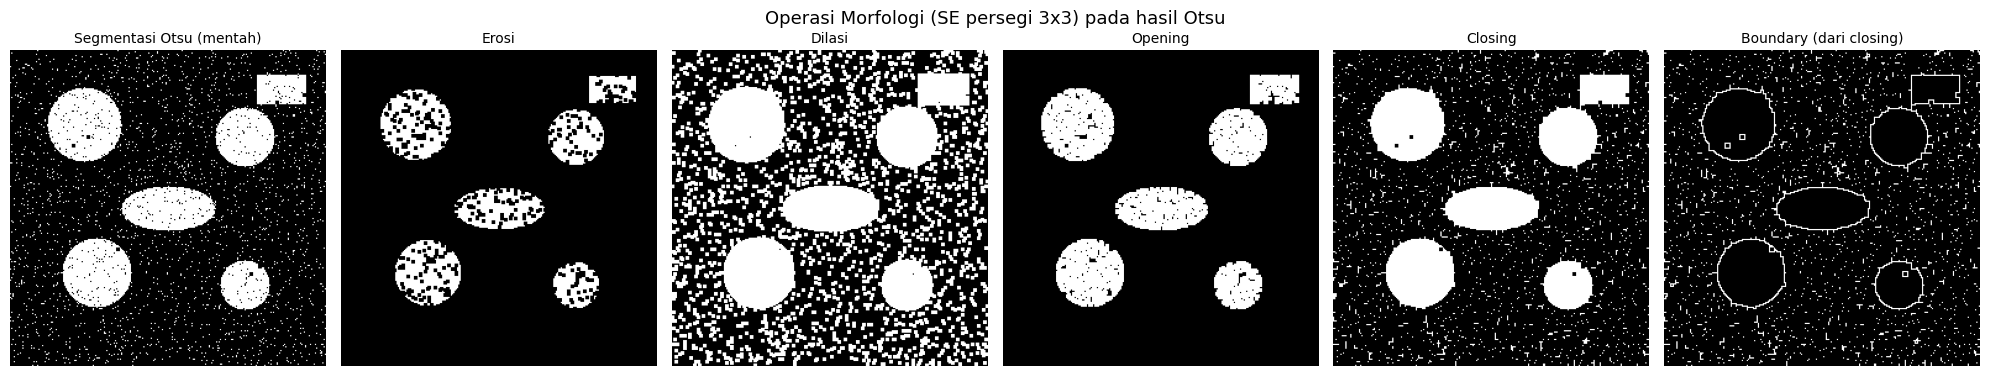

In [21]:
se3 = make_structuring_element(3, "square")
se5 = make_structuring_element(5, "disk")

m_erode = erode(seg_raw, se3)
m_dilate = dilate(seg_raw, se3)
m_open = opening(seg_raw, se3)
m_close = closing(seg_raw, se3)
m_boundary = boundary_extraction(m_close, se3)

fig, axes = plt.subplots(1, 6, figsize=(20, 3.8))
for ax, im, t in zip(
        axes,
        [seg_raw, m_erode, m_dilate, m_open, m_close, m_boundary],
        ["Segmentasi Otsu (mentah)", "Erosi", "Dilasi", "Opening", "Closing", "Boundary (dari closing)"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=1)
    ax.set_title(t, fontsize=10)
    ax.axis("off")
fig.suptitle("Operasi Morfologi (SE persegi 3x3) pada hasil Otsu", fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "01_operasi_morfologi.png"), dpi=120, bbox_inches="tight")
plt.show()

## 8. EKSPERIMEN 2: SEGMENTASI TANPA vs DENGAN MORFOLOGI

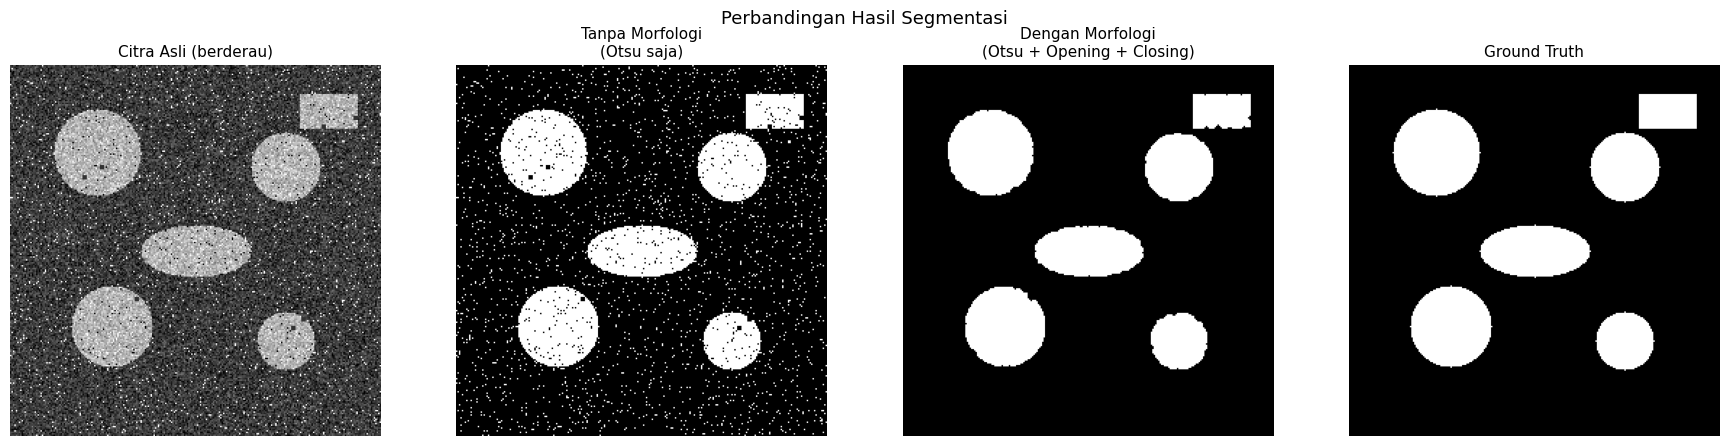

In [22]:
#Alur dengan morfologi: Otsu -> Opening (buang bintik noise) -> Closing (tutup lubang)
seg_morph = closing(opening(seg_raw, se3), se5)

fig, axes = plt.subplots(1, 4 if ground_truth is not None else 3, figsize=(18, 4.5))
panels = [(gray, "Citra Asli (berderau)", "gray"),
          (seg_raw, "Tanpa Morfologi\n(Otsu saja)", "gray"),
          (seg_morph, "Dengan Morfologi\n(Otsu + Opening + Closing)", "gray")]
if ground_truth is not None:
    panels.append((ground_truth, "Ground Truth", "gray"))
for ax, (im, t, cm) in zip(axes, panels):
    ax.imshow(im, cmap=cm)
    ax.set_title(t, fontsize=11)
    ax.axis("off")
fig.suptitle("Perbandingan Hasil Segmentasi", fontsize=13)
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "02_perbandingan_segmentasi.png"), dpi=120, bbox_inches="tight")
plt.show()

## 9. TABEL PERBANDINGAN KUANTITATIF

In [23]:
res_raw = evaluate(seg_raw, ground_truth)
res_morph = evaluate(seg_morph, ground_truth)

print(f"{'Metrik':32s} {'Tanpa Morfologi':>18s} {'Dengan Morfologi':>18s}")
print("-" * 70)
for k in res_raw:
    print(f"{k:32s} {str(res_raw[k]):>18s} {str(res_morph[k]):>18s}")

#simpan tabel sebagai CSV (tanpa pandas)
with open(os.path.join(OUTPUT_DIR, "perbandingan_metrik.csv"), "w", encoding="utf-8") as f:
    f.write("Metrik,Tanpa Morfologi,Dengan Morfologi\n")
    for k in res_raw:
        f.write(f"{k},{res_raw[k]},{res_morph[k]}\n")

Metrik                              Tanpa Morfologi   Dengan Morfologi
----------------------------------------------------------------------
Piksel objek                                  12941              11236
Jumlah komponen (semua)                        1674                  6
Komponen area >= 15px                             6                  6
Dice                                         0.8997             0.9906
IoU                                          0.8177             0.9814
Piksel salah (error)                           2444                213


## 10. EKSPERIMEN 3: PENGARUH UKURAN STRUCTURING ELEMENT (untuk analisis)

In [24]:
if ground_truth is not None:
    print("\nPengaruh ukuran SE (opening lalu closing, SE persegi):")
    print(f"{'Ukuran SE':12s} {'Dice':>8s} {'IoU':>8s} {'Komponen>=15px':>16s}")
    for s in [1, 3, 5, 7, 9]:
        se_t = make_structuring_element(s, "square")
        r = closing(opening(seg_raw, se_t), se_t)
        d, i = dice_iou(r, ground_truth)
        print(f"{str(s) + 'x' + str(s):12s} {d:8.4f} {i:8.4f} {count_objects(r, 15):16d}")


Pengaruh ukuran SE (opening lalu closing, SE persegi):
Ukuran SE        Dice      IoU   Komponen>=15px
1x1            0.8997   0.8177                6
3x3            0.9846   0.9697                6
5x5            0.9497   0.9042                6
7x7            0.8393   0.7231                5
9x9            0.6245   0.4540                6


## 11. SIMPAN HASIL & DOWNLOAD

In [25]:
def save_png(arr, name):
    plt.imsave(os.path.join(OUTPUT_DIR, name), arr, cmap="gray", vmin=0, vmax=1 if arr.max() <= 1 else 255)

plt.imsave(os.path.join(OUTPUT_DIR, "citra_asli.png"), gray, cmap="gray", vmin=0, vmax=255)
save_png(seg_raw, "segmentasi_tanpa_morfologi.png")
save_png(seg_morph, "segmentasi_dengan_morfologi.png")
if ground_truth is not None:
    save_png(ground_truth, "ground_truth.png")

try:
    import shutil
    shutil.make_archive("PCD_Assignment03_outputs", "zip", OUTPUT_DIR)
    from google.colab import files as gfiles
    gfiles.download("PCD_Assignment03_outputs.zip")
except Exception:
    print("Bukan di Colab / download dilewati. Hasil ada di folder:", OUTPUT_DIR)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. KESIMPULAN SINGKAT
- Otsu thresholding memisahkan objek dan latar secara otomatis, tetapi sangat sensitif terhadap noise: hasilnya penuh bintik (false positive di latar) dan lubang kecil di dalam objek (false negative).
- Opening (erosi->dilasi) efektif menghapus bintik noise kecil di latar tanpa banyak mengubah bentuk objek besar.
- Closing (dilasi->erosi) menutup lubang-lubang kecil di dalam objek sehingga objek utuh.
- Kombinasi Otsu + Opening + Closing memberikan hasil yang jauh lebih bersih dan lebih mendekati ground truth (Dice/IoU naik, jumlah komponen palsu turun drastis).
- Ukuran structuring element harus seimbang: terlalu kecil -> noise tersisa, terlalu besar -> detail/objek kecil ikut hilang dan sudut objek membulat.